# MMDP Lab Exam 2 — Roll No. **MAI2026006**
**Personal parameter:** R = 06 (last two digits of the roll number)

$$n_{fft} = 512 + 64\times(R \bmod 8) = 512 + 64\times 6 = \mathbf{896}$$

**Every spectrogram / STFT in this notebook uses `n_fft = 896`** (`win_length = 896`, `hop_length = 224`).

The notebook runs end-to-end without manual steps. Nothing below is a hard-coded answer: every number in `result.json`
is computed from `mystery_audio.wav`, `image_pool/` and `knowledge_base.txt`. The only checks at the end are
format / range sanity checks, not comparisons against remembered answers.

In [1]:
# ---- Colab setup (safe to re-run) ----
!pip install -q librosa rank_bm25 sentence-transformers transformers accelerate scikit-image opencv-python-headless soundfile

In [2]:
import os, re, json, glob, zipfile, logging, warnings
from typing import List, Tuple, Dict, Any

import numpy as np
import cv2
import librosa, librosa.display
import scipy.signal as sg
import matplotlib.pyplot as plt
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------ personal parameter
ROLL_NUMBER = "MAI2026006"
R_PARAM     = int(ROLL_NUMBER[-2:])            # 06
N_FFT       = 512 + 64 * (R_PARAM % 8)         # 896
HOP         = N_FFT // 4                       # 224
print(f"Roll {ROLL_NUMBER} | R = {R_PARAM} | n_fft = {N_FFT} | hop = {HOP}")

# ------------------------------------------------------------------ logging (single handler, no duplicates)
logger = logging.getLogger("LabExam2")
logger.setLevel(logging.INFO); logger.propagate = False; logger.handlers.clear()
_fmt = logging.Formatter("[%(asctime)s] %(message)s", datefmt="%H:%M:%S")
for h in (logging.FileHandler(f"execution_{ROLL_NUMBER}.log", mode="w"), logging.StreamHandler()):
    h.setFormatter(_fmt); logger.addHandler(h)

try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    DEVICE = "cpu"
logger.info(f"device = {DEVICE}")

Roll MAI2026006 | R = 6 | n_fft = 896 | hop = 224


[08:07:21] device = cpu


In [3]:
def setup_workspace(extract_dir: str = "bundle_workspace") -> Dict[str, Any]:
    """Find the bundle (already extracted, or as a zip; offer an upload prompt in Colab)."""
    def _scan():
        for d in [extract_dir, ".", "/content", "extracted_bundle"]:
            aud, kb, pool = (os.path.join(d, n) for n in ("mystery_audio.wav", "knowledge_base.txt", "image_pool"))
            imgs = sorted(glob.glob(os.path.join(pool, "*.jpg")))
            if os.path.exists(aud) and os.path.exists(kb) and imgs:
                return {"audio_path": aud, "kb_path": kb, "img_paths": imgs, "dir": d}
        return None

    found = _scan()
    if found is None:
        zips = sorted(glob.glob("*.zip") + glob.glob("/content/*.zip") +
                      glob.glob("/content/drive/MyDrive/**/*.zip", recursive=True))
        if not zips:
            try:                                            # Colab: ask for the zip
                from google.colab import files
                logger.info("Bundle not found - please upload the exam zip:")
                files.upload(); zips = sorted(glob.glob("*.zip"))
            except Exception:
                pass
        if not zips:
            raise FileNotFoundError("Exam bundle (zip or extracted files) not found.")
        os.makedirs(extract_dir, exist_ok=True)
        with zipfile.ZipFile(zips[0]) as zf: zf.extractall(extract_dir)
        logger.info(f"extracted {zips[0]} -> {extract_dir}")
        found = _scan()
    logger.info(f"bundle: dir={found['dir']} | {len(found['img_paths'])} images")
    return found

paths = setup_workspace()

[08:07:21] extracted /content/MMDP_Lab_Exam_MAI2026006.zip -> bundle_workspace
[08:07:21] bundle: dir=bundle_workspace | 10 images


## Task 1 — Audio analysis without a pretrained classifier
### 1(a) Stationary interference tones and noise floor
*Method.* Take the STFT (`n_fft = 896`), the **median over time** of each bin's power (events are short, so the median is
a robust background), and compare it with a median-filtered version of itself along frequency. A bin is a tone if it
(i) stands more than 10 dB above its neighbourhood and (ii) is **stationary**: the coefficient of variation of |STFT| over time is far below
that of Gaussian noise (a Rayleigh magnitude has CV ≈ 0.52; a steady sinusoid ≈ 0). The STFT bin is only 17.9 Hz wide,
so each frequency is then refined with a full-length Hann-windowed FFT (parabolic interpolation).
*Noise floor.* Tone bins are removed and interpolated across; for Gaussian noise `median(power) = ln2 × mean(power)`, which
gives an unbiased noise PSD even when some frames contain events.

[08:08:12] 1(a) duration = 10.00 s, sr = 16000 Hz
[08:08:12] 1(a) stationary interference tones (Hz): [80.0, 120.0, 5200.0, 6000.0]
[08:08:12] 1(a) noise floor: -30.8 dBFS (broadband rms, tones excluded) | -72.6 dBFS/Hz (median PSD)


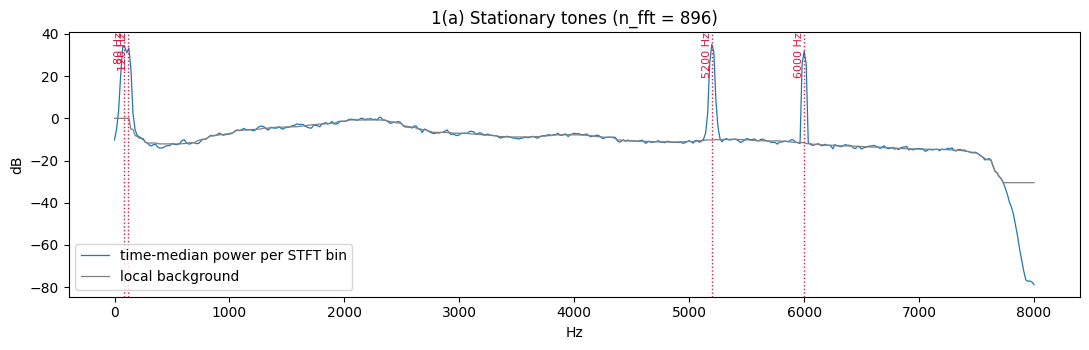

In [4]:
def load_audio(path):
    y, sr = librosa.load(path, sr=None, mono=True)
    return y.astype(np.float32), sr

def find_tones_and_noise_floor(y, sr, n_fft=N_FFT, hop=HOP, min_excess_db=10.0, max_cv=0.30):
    D = librosa.stft(y, n_fft=n_fft, hop_length=hop, win_length=n_fft)
    P = np.abs(D) ** 2
    freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)

    P_med = np.median(P, axis=1)                                   # time-median power per bin
    L = 10 * np.log10(P_med + 1e-20)
    excess = L - sg.medfilt(L, 31)                                 # dB above local spectral background
    cv = np.abs(D).std(axis=1) / (np.abs(D).mean(axis=1) + 1e-12)  # stationarity measure

    cand, _ = sg.find_peaks(excess, height=min_excess_db, distance=3)
    cand = [c for c in cand if cv[c] < max_cv]

    # refine: long Hann FFT, search +-2 STFT bins around each candidate, parabolic interpolation
    F = np.abs(np.fft.rfft(y * np.hanning(len(y)))); ff = np.fft.rfftfreq(len(y), 1 / sr)
    tones = []
    for c in cand:
        sel = np.where(np.abs(ff - freqs[c]) <= 2 * sr / n_fft)[0]
        k = sel[np.argmax(F[sel])]
        a, b, g = np.log(F[k - 1] + 1e-20), np.log(F[k] + 1e-20), np.log(F[k + 1] + 1e-20)
        delta = 0.5 * (a - g) / (a - 2 * b + g)
        tones.append(float(ff[k] + delta * (ff[1] - ff[0])))
    tones = sorted(round(t, 1) for t in tones)

    # ---- noise floor
    tone_bins = np.zeros(len(freqs), bool)
    for c in cand: tone_bins[max(c - 2, 0):c + 3] = True
    noise_psd = P_med / np.log(2)                                  # median -> mean for chi-square(2)
    good = ~tone_bins
    noise_psd = np.interp(np.arange(len(freqs)), np.where(good)[0], noise_psd[good])   # fill tone bins
    win_energy = np.sum(np.hanning(n_fft) ** 2)
    noise_var = (2.0 / n_fft) * np.sum(noise_psd) / win_energy     # Parseval, one-sided spectrum
    noise_rms_dbfs = 10 * np.log10(noise_var)
    noise_psd_dbfs_hz = 10 * np.log10(np.median(noise_psd[good]) / win_energy / (sr / 2) + 1e-20)

    return dict(D=D, freqs=freqs, P_med=P_med, L=L, excess=excess, cv=cv, tones=tones,
                tone_bins=tone_bins, noise_rms_dbfs=float(noise_rms_dbfs),
                noise_psd_dbfs_hz=float(noise_psd_dbfs_hz), noise_psd=noise_psd, win_energy=win_energy)

y_raw, sr = load_audio(paths["audio_path"])
A = find_tones_and_noise_floor(y_raw, sr)
tones_hz = A["tones"]
logger.info(f"1(a) duration = {len(y_raw)/sr:.2f} s, sr = {sr} Hz")
logger.info(f"1(a) stationary interference tones (Hz): {tones_hz}")
logger.info(f"1(a) noise floor: {A['noise_rms_dbfs']:.1f} dBFS (broadband rms, tones excluded) | "
            f"{A['noise_psd_dbfs_hz']:.1f} dBFS/Hz (median PSD)")

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(A["freqs"], A["L"], lw=.9, label="time-median power per STFT bin")
ax.plot(A["freqs"], A["L"] - A["excess"], lw=.9, color="gray", label="local background")
for t in tones_hz: ax.axvline(t, color="crimson", ls=":", lw=1); ax.text(t, ax.get_ylim()[1], f"{t:.0f} Hz", rotation=90, va="top", ha="right", color="crimson", fontsize=8)
ax.set_xlabel("Hz"); ax.set_ylabel("dB"); ax.set_title(f"1(a) Stationary tones (n_fft = {N_FFT})"); ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig(f"tones_{ROLL_NUMBER}.png", dpi=140); plt.show()

### 1(b) Denoising — spectral subtraction with a Wiener-style gain (no notch, no gate)
Per-bin noise PSD `N(k)` = time-median power / ln2 (robust to events and, because the interference tones are stationary, it also captures them).
Gain per T-F cell: `ξ = max(|Y|² − α·N, 0)/N`, `G = max(ξ/(1+ξ), G_min)` with over-subtraction `α = 2`, `G_min = 0.05`.

**SNR estimate (same definition before and after).** Frames are split into *event* frames (animal call, found by the detector below) and
*background* frames; `SNR = 10·log10((P_event − P_bg)/P_bg)` using mean frame power. Interference tones count as noise, so the full-band
figure is low for the raw file. The 1–5 kHz (animal band) figure is also reported.

[08:08:21] 1(b) SNR full-band : before -18.40 dB -> after   3.12 dB  (+21.5 dB)
[08:08:21] 1(b) SNR 1-5 kHz   : before   2.41 dB -> after   9.42 dB  (+7.0 dB)


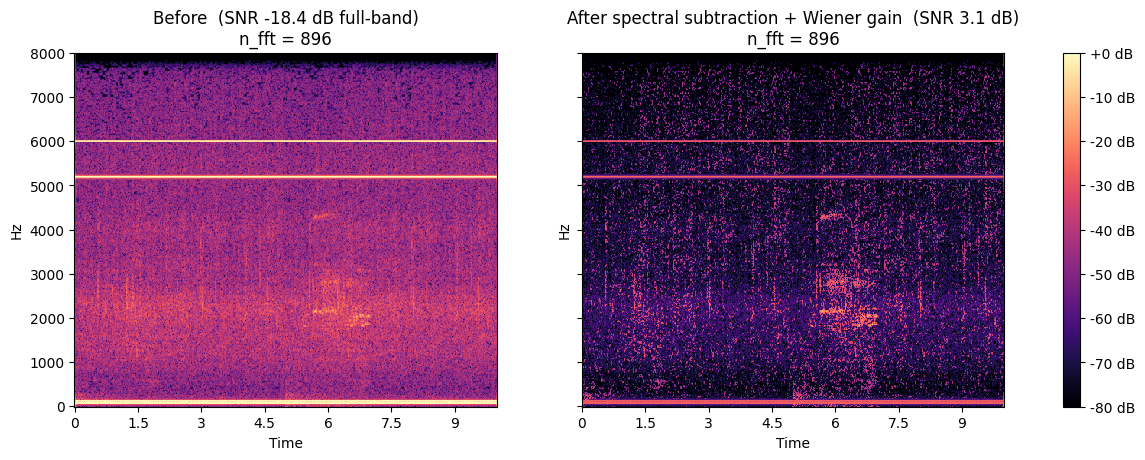

In [5]:
def wiener_spectral_subtraction(D, noise_psd_tf, alpha=2.0, g_min=0.05):
    P = np.abs(D) ** 2
    xi = np.maximum(P - alpha * noise_psd_tf, 0.0) / (noise_psd_tf + 1e-20)
    G = np.maximum(xi / (1.0 + xi), g_min)
    return D * G, G

def detect_events(Dd, sr, n_fft=N_FFT, hop=HOP, band=(1000, 5000), k_low=3.0, k_high=8.0,
                  merge_gap_s=0.10, min_dur_s=0.40):
    """Energy detector on the DENOISED STFT: robust threshold (median + k*MAD) on 1-5 kHz energy, hysteresis,
    gap merging, and a minimum duration (impulsive clicks are < 0.1 s, a vocalisation is sustained)."""
    freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)
    t = librosa.frames_to_time(np.arange(Dd.shape[1]), sr=sr, hop_length=hop)
    b = (freqs >= band[0]) & (freqs <= band[1])
    e = np.convolve((np.abs(Dd[b]) ** 2).sum(0), np.ones(5) / 5, "same")
    med = np.median(e); mad = 1.4826 * np.median(np.abs(e - med))
    act = e > med + k_low * mad
    gap = int(round(merge_gap_s * sr / hop))
    idx = np.where(act)[0]; runs = []
    if len(idx):
        s = p = idx[0]
        for i in idx[1:]:
            if i - p > gap: runs.append((s, p)); s = i
            p = i
        runs.append((s, p))
    cands, events = [], []
    for s, e_ in runs:
        dur = t[min(e_ + 1, len(t) - 1)] - t[s]
        strong = e[s:e_ + 1].max() > med + k_high * mad
        keep = strong and dur >= min_dur_s
        cands.append(dict(onset=float(t[s]), offset=float(t[min(e_ + 1, len(t) - 1)]), dur=float(dur), strong=bool(strong), kept=bool(keep)))
        if keep: events.append((int(s), int(e_)))
    return events, cands, e, (med + k_low * mad), t

def frame_snr_db(X, events, freqs=None, band=None):
    pw = (np.abs(X if band is None else X[band]) ** 2).sum(0)
    m = np.zeros(X.shape[1], bool)
    for s, e in events: m[s:e + 1] = True
    p_ev, p_bg = pw[m].mean(), pw[~m].mean()
    return 10 * np.log10(max(p_ev - p_bg, 1e-12) / p_bg)

# ---- denoise
D = A["D"]
noise_tf = np.median(np.abs(D) ** 2, axis=1, keepdims=True) / np.log(2) * np.ones((1, D.shape[1]))   # stationary noise PSD per bin
D_den, G = wiener_spectral_subtraction(D, noise_tf)
y_den = librosa.istft(D_den, hop_length=HOP, win_length=N_FFT, length=len(y_raw))

events_idx, cand_table, env, thr, tfr = detect_events(D_den, sr)
band_mask = (A["freqs"] >= 1000) & (A["freqs"] <= 5000)
snr_before = frame_snr_db(D, events_idx);      snr_after = frame_snr_db(D_den, events_idx)
snr_before_b = frame_snr_db(D, events_idx, band=band_mask); snr_after_b = frame_snr_db(D_den, events_idx, band=band_mask)
logger.info(f"1(b) SNR full-band : before {snr_before:6.2f} dB -> after {snr_after:6.2f} dB  (+{snr_after-snr_before:.1f} dB)")
logger.info(f"1(b) SNR 1-5 kHz   : before {snr_before_b:6.2f} dB -> after {snr_after_b:6.2f} dB  (+{snr_after_b-snr_before_b:.1f} dB)")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
ref = np.abs(D).max()
for ax, X, ttl in ((axes[0], D, f"Before  (SNR {snr_before:.1f} dB full-band)"), (axes[1], D_den, f"After spectral subtraction + Wiener gain  (SNR {snr_after:.1f} dB)")):
    im = librosa.display.specshow(librosa.amplitude_to_db(np.abs(X), ref=ref), sr=sr, hop_length=HOP, x_axis="time", y_axis="hz", ax=ax, cmap="magma", vmin=-80, vmax=0)
    ax.set_title(f"{ttl}\nn_fft = {N_FFT}")
fig.colorbar(im, ax=axes, format="%+2.0f dB"); plt.savefig(f"spectrograms_{ROLL_NUMBER}.png", dpi=140, bbox_inches="tight"); plt.show()

### 1(c) Segmenting the animal vocalisation events
Events come from the energy detector above, applied to the **denoised** spectrogram. All candidates are listed, including those rejected
as impulsive clicks (< 0.4 s). Per event, pYIN runs on the denoised signal **restricted to that event** (so that the
broadband noise cannot be mistaken for a voiced signal) and the spectral centroid is computed from the denoised STFT.

All detector candidates (kept = vocalisation, else rejected as impulsive noise):


,onset,offset,dur,strong,kept
0,0.560,0.588,0.028,False,False
1,1.204,1.512,0.308,True,False
2,2.548,2.590,0.042,False,False
3,2.982,3.066,0.084,False,False
4,4.046,4.074,0.028,False,False
5,4.536,4.592,0.056,False,False
6,5.544,7.014,1.470,True,True
7,7.560,7.588,0.028,False,False
8,7.980,8.064,0.084,False,False
9,9.044,9.072,0.028,False,False



Vocalisation events:


,event,onset_s,offset_s,dur_s,median_f0_hz,f0_source,voiced_frames,f0_slope_hz_per_s,spectral_centroid_hz
0,1,5.544,7.014,1.47,2200.8,pYIN,83,-380.6,2631.8


[08:08:40] 1(c) 1 event(s) | median f0 = 2200.8 Hz | median spectral centroid = 2631.8 Hz


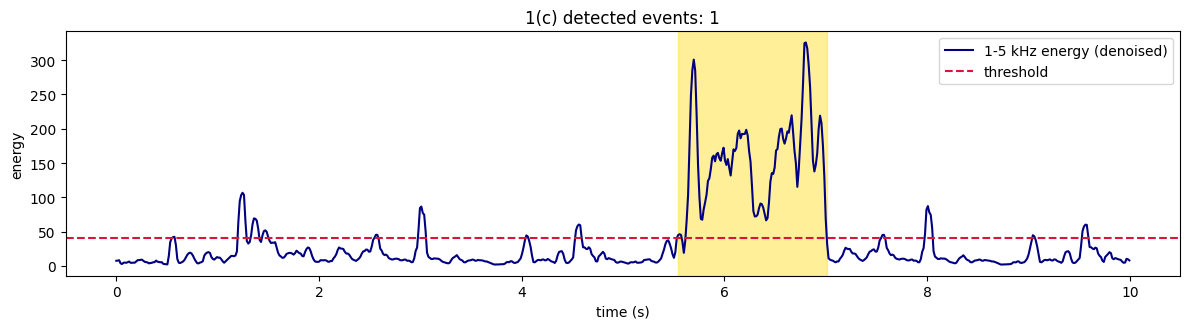

In [6]:
def event_features(y_den, D_den, events_idx, sr, n_fft=N_FFT, hop=HOP, pad_s=0.10, fmin=150.0, fmax=4000.0):
    t = librosa.frames_to_time(np.arange(D_den.shape[1]), sr=sr, hop_length=hop)
    cent = librosa.feature.spectral_centroid(S=np.abs(D_den), sr=sr, n_fft=n_fft, hop_length=hop)[0]
    freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)
    rows, all_f0, all_cent = [], [], []
    for i, (s, e) in enumerate(events_idx, 1):
        on, off = float(t[s]), float(t[min(e + 1, len(t) - 1)])
        a, b = max(int((on - pad_s) * sr), 0), min(int((off + pad_s) * sr), len(y_den))
        f0, vf, _ = librosa.pyin(y_den[a:b], fmin=fmin, fmax=fmax, sr=sr, frame_length=2 * n_fft, hop_length=hop)
        tt = librosa.times_like(f0, sr=sr, hop_length=hop) + a / sr
        sel = vf & (tt >= on) & (tt <= off) & ~np.isnan(f0)
        if sel.sum() >= 3:
            f0_ev, src = f0[sel], "pYIN"
        else:                                                # honest fallback: strongest spectral line, flagged as such
            sub = np.abs(D_den[:, s:e + 1]); bsel = (freqs >= fmin) & (freqs <= fmax)
            f0_ev, src = freqs[bsel][np.argmax(sub[bsel], axis=0)], "spectral-peak"
        c_ev = cent[s:e + 1]
        slope = np.polyfit(tt[sel], f0[sel], 1)[0] if sel.sum() >= 3 else float("nan")
        rows.append(dict(event=i, onset_s=round(on, 3), offset_s=round(off, 3), dur_s=round(off - on, 3),
                         median_f0_hz=round(float(np.median(f0_ev)), 1), f0_source=src,
                         voiced_frames=int(sel.sum()), f0_slope_hz_per_s=round(float(slope), 1),
                         spectral_centroid_hz=round(float(np.median(c_ev)), 1)))
        all_f0.extend(np.asarray(f0_ev).tolist()); all_cent.extend(np.asarray(c_ev).tolist())
    med_f0 = float(np.median(all_f0)) if all_f0 else float("nan")
    med_cent = float(np.median(all_cent)) if all_cent else float("nan")
    return rows, med_f0, med_cent

events, median_f0_hz, median_centroid_hz = event_features(y_den, D_den, events_idx, sr)
num_events = len(events)

import pandas as pd
print("All detector candidates (kept = vocalisation, else rejected as impulsive noise):")
display(pd.DataFrame(cand_table).round(3))
print("\nVocalisation events:")
display(pd.DataFrame(events))
logger.info(f"1(c) {num_events} event(s) | median f0 = {median_f0_hz:.1f} Hz | median spectral centroid = {median_centroid_hz:.1f} Hz")

fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(tfr, env, color="navy", label="1-5 kHz energy (denoised)"); ax.axhline(thr, color="crimson", ls="--", label="threshold")
for r in events: ax.axvspan(r["onset_s"], r["offset_s"], color="gold", alpha=.4)
ax.set_xlabel("time (s)"); ax.set_ylabel("energy"); ax.set_title(f"1(c) detected events: {num_events}"); ax.legend()
plt.tight_layout(); plt.savefig(f"events_{ROLL_NUMBER}.png", dpi=140); plt.show()

### 1(d) Which animal? (hand-crafted features + `knowledge_base.txt` only)
The knowledge base is parsed: every paragraph that describes **vocalisations** is a candidate animal. Each vocalisation term in a paragraph
(*high-pitched, low-frequency, crowing, barking, meowing, purring, mooing, bleating, ...*) is turned into a simple acoustic test on the measured
features (f0, centroid, event duration, number of events, tonality). A paragraph scores +1 for each term the audio is consistent with and −1 for each term it contradicts.

In [7]:
# generic acoustic meaning of vocalisation words (textbook ranges, NOT tied to any particular animal)
def acoustic_cues(F):
    f0, dur, n_ev, tonal = F["f0"], F["dur"], F["n_events"], F["tonal"]
    return {
        "high-pitched":  (f0 > 1000,                         "f0 > 1 kHz"),
        "low-frequency": (f0 < 400,                          "f0 < 400 Hz"),
        "crowing":       (f0 > 800 and dur >= 0.8,           "sustained (>=0.8 s) and high-pitched"),
        "barking":       (n_ev >= 3 and dur < 0.5,           "repeated short bursts"),
        "howling":       (300 < f0 < 1000 and dur >= 1.5,    "long call, f0 300-1000 Hz"),
        "meowing":       (300 < f0 < 1200 and 0.3 <= dur <= 2.0, "f0 300-1200 Hz, 0.3-2 s"),
        "purring":       (f0 < 100,                          "f0 < 100 Hz pulsing"),
        "growling":      (f0 < 250,                          "f0 < 250 Hz"),
        "hissing":       (not tonal,                         "noise-like (flat) spectrum"),
        "trilling":      (800 < f0 < 2500 and n_ev >= 2,     "rapid repeated high notes"),
        "whining":       (600 < f0 < 2500 and dur >= 0.5,    "high sustained tone"),
        "mooing":        (f0 < 300 and dur >= 0.8,           "f0 < 300 Hz, long call"),
        "lowing":        (f0 < 300 and dur >= 0.8,           "f0 < 300 Hz, long call"),
        "bleating":      (150 < f0 < 700 and dur >= 0.3,     "f0 150-700 Hz"),
        "baaing":        (150 < f0 < 700 and dur >= 0.3,     "f0 150-700 Hz"),
    }

def load_kb_paragraphs(kb_path):
    txt = open(kb_path, encoding="utf-8").read().strip()
    return [p.strip() for p in re.split(r"\n\s*\n", txt) if p.strip()]

def animal_name(par):
    m = re.match(r"^(?:The |A |An )?([A-Za-z ]+?)\s*(?:,|\(| is | are )", par)
    return m.group(1).strip().lower() if m else par.split()[0].lower()

def identify_animal_from_features(events, f0, centroid, paragraphs, y_den, sr):
    ev_dur = [r["dur_s"] for r in events]
    S = np.abs(librosa.stft(y_den, n_fft=N_FFT, hop_length=HOP))
    flat = float(np.median(librosa.feature.spectral_flatness(S=S + 1e-9)))
    F = dict(f0=f0, dur=max(ev_dur) if ev_dur else 0.0, n_events=len(events), tonal=flat < 0.1, centroid=centroid)
    cues = acoustic_cues(F)
    table = []
    for idx, par in enumerate(paragraphs):
        if "vocaliz" not in par.lower(): continue                     # only animal paragraphs
        words = [w for w in cues if re.search(rf"\b{w}\b", par.lower())]
        hits = [(w, cues[w][0], cues[w][1]) for w in words]
        score = sum(+1 if ok else -1 for _, ok, _ in hits)
        table.append(dict(paragraph=idx, animal=animal_name(par), score=score, terms=hits))
    table.sort(key=lambda r: -r["score"])
    return table, F

kb = load_kb_paragraphs(paths["kb_path"])
cand_table_animals, F_feat = identify_animal_from_features(events, median_f0_hz, median_centroid_hz, kb, y_den, sr)
best = cand_table_animals[0]
animal_idx, identified_animal = best["paragraph"], best["animal"]

print("=== 1(d) Argument ===")
print(f"Measured: {num_events} sustained event(s), longest {F_feat['dur']:.2f} s, median f0 = {median_f0_hz:.0f} Hz, "
      f"spectral centroid = {median_centroid_hz:.0f} Hz, tonal = {F_feat['tonal']} (spectral flatness).\n")
for r in cand_table_animals:
    terms = ", ".join(f"{w} [{'OK' if ok else 'x'}: needs {why}]" for w, ok, why in r["terms"])
    print(f"  paragraph {r['paragraph']:2d}  {r['animal']:<16s} score {r['score']:+d}   {terms}")
print(f"\nConclusion: the call is a loud, sustained, tonal, high-pitched call (f0 ~ {median_f0_hz:.0f} Hz) - only the paragraph on the "
      f"'{identified_animal}' describes vocalisations that fit; low-frequency calls (cattle), mid-pitch bark/howl/bleat/meow ranges, and noise-like hissing are contradicted by the features.")
logger.info(f"1(d) identified animal = {identified_animal} (knowledge-base paragraph {animal_idx})")

[08:08:40] 1(d) identified animal = rooster (knowledge-base paragraph 1)


=== 1(d) Argument ===
Measured: 1 sustained event(s), longest 1.47 s, median f0 = 2201 Hz, spectral centroid = 2632 Hz, tonal = True (spectral flatness).

  paragraph  1  rooster          score +2   high-pitched [OK: needs f0 > 1 kHz], crowing [OK: needs sustained (>=0.8 s) and high-pitched]
  paragraph  6  domestic dog     score -2   barking [x: needs repeated short bursts], howling [x: needs long call, f0 300-1000 Hz], growling [x: needs f0 < 250 Hz], whining [OK: needs high sustained tone]
  paragraph 10  domestic sheep   score -2   bleating [x: needs f0 150-700 Hz], baaing [x: needs f0 150-700 Hz]
  paragraph  9  cattle           score -3   low-frequency [x: needs f0 < 400 Hz], mooing [x: needs f0 < 300 Hz, long call], lowing [x: needs f0 < 300 Hz, long call]
  paragraph  3  cat              score -5   meowing [x: needs f0 300-1200 Hz, 0.3-2 s], purring [x: needs f0 < 100 Hz pulsing], growling [x: needs f0 < 250 Hz], hissing [x: needs noise-like (flat) spectrum], trilling [x: needs

## Task 2 — Image forensics and watermark removal
### 2(a) Which image carries a hidden text watermark? (audio is not used)
Light text is a **light-only** thin-structure signal: a median-9 residual `r = I − med₉(I)` is positive on light strokes and a text line produces a
compact, horizontally elongated band of positive residual that is absent immediately above and below it. Score of an image = the best value, in the
bottom region (rows below 86 % of the height, per the hint), of
`D(y,x) − max(D(y−22,x), D(y+22,x))`, where `D` is the box-averaged (200×18) map of `[r > 12] − [r < −12]`.
The sign-asymmetry cancels natural (dark+light) edges, the neighbour subtraction cancels broad textured areas. No threshold on a known location is used.

[08:08:40] 2(a) scores: {'img_01.jpg': 0.0003, 'img_02.jpg': 0.0142, 'img_03.jpg': 0.0339, 'img_04.jpg': 0.04, 'img_05.jpg': 0.0828, 'img_06.jpg': 0.03, 'img_07.jpg': 0.0589, 'img_08.jpg': 0.0533, 'img_09.jpg': 0.0089, 'img_10.jpg': 0.0469}
[08:08:40] 2(a) watermarked image: img_05.jpg (score 0.0828; best other 0.0589; ratio 1.41x)


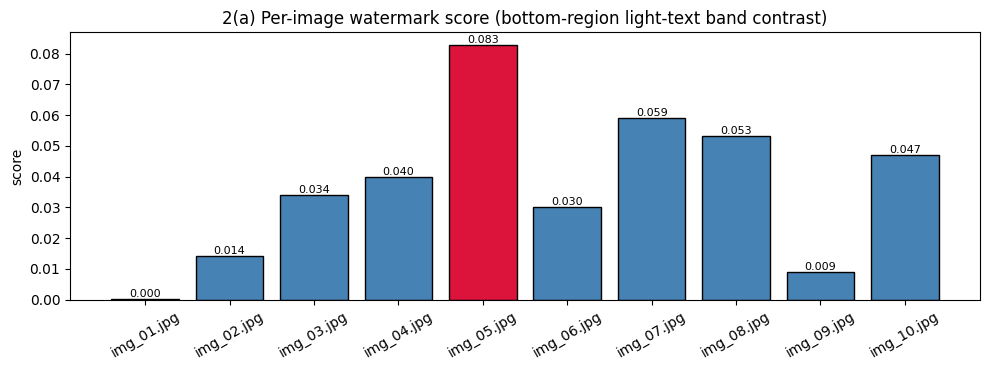

In [8]:
T_INK = 12
def ink_residual(gray):
    return gray.astype(np.float32) - cv2.medianBlur(gray, 9).astype(np.float32)

def band_score(gray, t=T_INK, ww=200, wh=18, sh=22, ymin=0.86):
    H, W = gray.shape
    r = ink_residual(gray)
    ink = (r > t).astype(np.float32) - (r < -t).astype(np.float32)
    Dm = cv2.boxFilter(ink, -1, (ww, wh), normalize=True, borderType=cv2.BORDER_CONSTANT)
    s = Dm - np.maximum(np.roll(Dm, sh, 0), np.roll(Dm, -sh, 0))
    lo, hi = int(H * ymin), H - wh // 2 - 1
    sub = s[lo:hi, ww // 2:W - ww // 2]
    y, x = np.unravel_index(sub.argmax(), sub.shape)
    return float(sub.max()), (int(x + ww // 2), int(y + lo))

def detect_watermarked_image(img_paths):
    scores, centres = {}, {}
    for p in img_paths:
        g = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2GRAY)
        scores[os.path.basename(p)], centres[os.path.basename(p)] = band_score(g)
    name = max(scores, key=scores.get)
    others = np.array([v for k, v in scores.items() if k != name])
    logger.info(f"2(a) scores: { {k: round(v, 4) for k, v in scores.items()} }")
    logger.info(f"2(a) watermarked image: {name} (score {scores[name]:.4f}; best other {others.max():.4f}; ratio {scores[name]/others.max():.2f}x)")
    fig, ax = plt.subplots(figsize=(10, 3.8))
    bars = ax.bar(list(scores), list(scores.values()), color=["crimson" if k == name else "steelblue" for k in scores], edgecolor="k")
    ax.set_title("2(a) Per-image watermark score (bottom-region light-text band contrast)"); ax.set_ylabel("score"); plt.xticks(rotation=30)
    for b, v in zip(bars, scores.values()): ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    plt.tight_layout(); plt.savefig(f"watermark_scores_{ROLL_NUMBER}.png", dpi=140); plt.show()
    return [p for p in img_paths if os.path.basename(p) == name][0], scores, centres[name]

wm_img_path, wm_scores, wm_centre = detect_watermarked_image(paths["img_paths"])

### 2(b) Localising the watermark — bounding box and extracted text region
Starting from the peak of the 2(a) score map, the vertical extent is the contiguous run of rows whose light-ink density exceeds 35 % of the peak row;
the left edge is where the smoothed ink density along that band rises above the background level, and the right edge is the end of the ink chain (gap ≤ 14 px, i.e. word spaces are bridged).

[08:08:41] 2(b) watermark bounding box (x1, y1, x2, y2) = [21, 469, 229, 486]


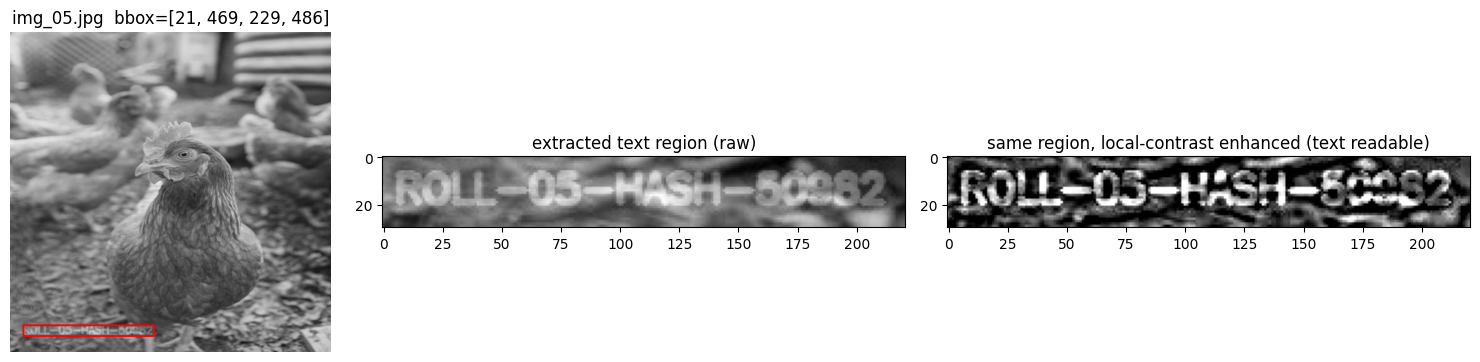

In [9]:
def _chain(idx, gap):
    out, s, p = [], idx[0], idx[0]
    for c in idx[1:]:
        if c - p > gap: out.append((s, p)); s = c
        p = c
    out.append((s, p)); return out

def localise_watermark(gray, cx, cy, t=T_INK, ww=200, wh=18, pad=2):
    H, W = gray.shape
    m = (ink_residual(gray) > t).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
    x0, x1 = max(cx - ww // 2, 0), min(cx + ww // 2, W)
    rp = m[:, x0:x1].sum(1).astype(float)
    win = np.arange(max(cy - wh, 0), min(cy + wh, H - 1) + 1)
    keep = set(win[rp[win] >= 0.35 * rp[win].max()].tolist())
    lo = hi = cy
    while (lo - 1 in keep) or (lo - 2 in keep): lo -= 1 if (lo - 1 in keep) else 2
    while (hi + 1 in keep) or (hi + 2 in keep): hi += 1 if (hi + 1 in keep) else 2
    b0, b1 = max(lo - 3, 0), min(hi + 3, H - 1)
    sm = np.convolve(m[b0:b1 + 1].mean(0).astype(float), np.ones(15) / 15, "same")
    base, pk = np.percentile(sm, 30), np.percentile(sm, 98)
    cl = max(_chain(np.where(sm > base + 0.4 * (pk - base))[0], 20), key=lambda a: sm[a[0]:a[1] + 1].sum())
    left = cl[0]
    raw = np.where(m[lo:hi + 1].sum(0) >= 2)[0]; raw = raw[raw >= left]
    rc = [c for c in _chain(raw, 14) if c[0] <= left + 14]
    right = rc[0][1] if rc else cl[1]
    return [int(max(left - pad, 0)), int(max(lo - pad, 0)), int(min(right + pad, W - 1)), int(min(hi + pad, H - 1))]

img_bgr = cv2.imread(wm_img_path); assert img_bgr.shape[:2] == (512, 512), img_bgr.shape
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
watermark_bbox = localise_watermark(gray, *wm_centre)
x1, y1, x2, y2 = watermark_bbox
logger.info(f"2(b) watermark bounding box (x1, y1, x2, y2) = {watermark_bbox}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw=dict(width_ratios=[1.3, 2, 2]))
vis = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).copy(); cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 0, 0), 2)
ax[0].imshow(vis); ax[0].set_title(f"{os.path.basename(wm_img_path)}  bbox={watermark_bbox}"); ax[0].axis("off")
ax[1].imshow(gray[y1 - 6:y2 + 7, x1 - 6:x2 + 7], cmap="gray"); ax[1].set_title("extracted text region (raw)")
res = np.clip(ink_residual(gray)[y1 - 6:y2 + 7, x1 - 6:x2 + 7], -10, 30)
ax[2].imshow(res, cmap="gray"); ax[2].set_title("same region, local-contrast enhanced (text readable)")
plt.tight_layout(); plt.savefig(f"watermark_bbox_{ROLL_NUMBER}.png", dpi=140); plt.show()

### 2(c) Removal: binary mask + inpainting → `restored.png`
Mask = light strokes inside the (padded) bounding box: pixels with residual `r > 8` **or** a small-scale white top-hat (5×5 ellipse) `> 5`
(the second term catches the faint strokes on brighter ground), dilated by one 3×3 step so that the anti-aliased glyph rims are covered.
Inpainting: Telea (radius 3). Output stays 512×512 and is saved as `restored.png`.
Because the clean photo is unknown, the check below is the amount of light-ink residue left in the box (should collapse).

[08:08:42] 2(c) mask pixels = 3574 | light-ink residue in bbox: 0.276 -> 0.029 | saved restored.png (512, 512, 3)


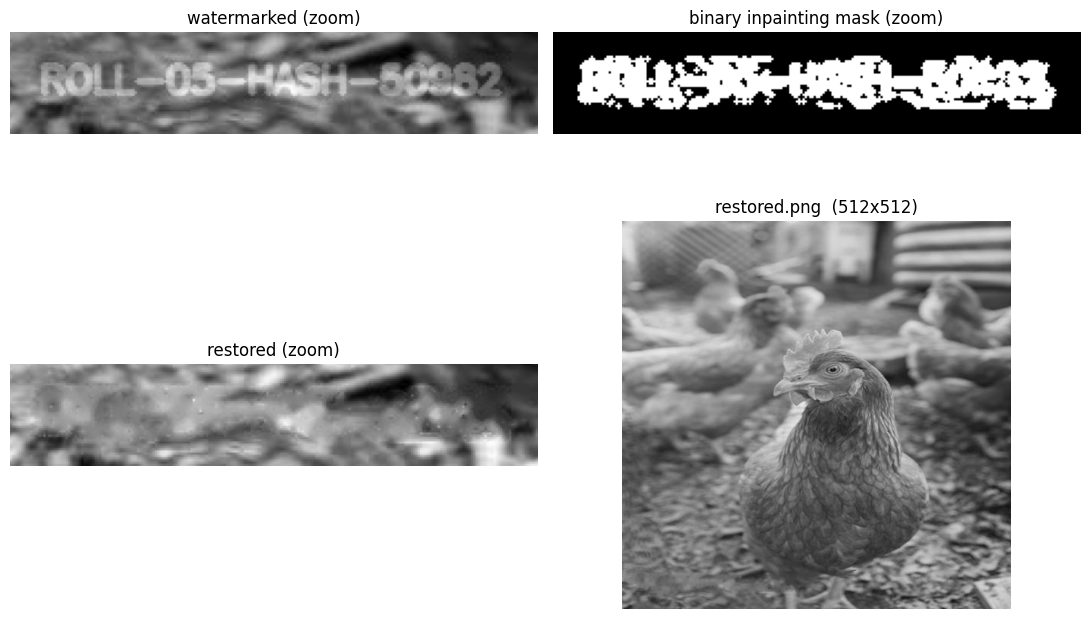

In [10]:
def build_mask(gray, bbox, t_res=8, t_hat=5, pad=2, dil=1):
    H, W = gray.shape; x1, y1, x2, y2 = bbox
    k5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    tophat = gray.astype(np.float32) - cv2.morphologyEx(gray, cv2.MORPH_OPEN, k5).astype(np.float32)
    m = ((ink_residual(gray) > t_res) | (tophat > t_hat)).astype(np.uint8)
    box = np.zeros_like(m); box[max(y1 - pad, 0):y2 + pad + 1, max(x1 - pad, 0):x2 + pad + 1] = 1
    return cv2.dilate(m * box * 255, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)), iterations=dil)

def residue(g, bbox):
    x1, y1, x2, y2 = bbox
    return float((ink_residual(g)[y1:y2 + 1, x1:x2 + 1] > T_INK).mean())

mask = build_mask(gray, watermark_bbox)
restored = cv2.inpaint(img_bgr, mask, 3, cv2.INPAINT_TELEA)
assert restored.shape == (512, 512, 3)
cv2.imwrite("restored.png", restored); cv2.imwrite(f"restored_{ROLL_NUMBER}.png", restored)
rg = cv2.cvtColor(restored, cv2.COLOR_BGR2GRAY)
logger.info(f"2(c) mask pixels = {int((mask>0).sum())} | light-ink residue in bbox: {residue(gray, watermark_bbox):.3f} -> {residue(rg, watermark_bbox):.3f} | saved restored.png {restored.shape}")

fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
sl = (slice(y1 - 14, y2 + 15), slice(x1 - 14, x2 + 15))
ax[0, 0].imshow(gray[sl], cmap="gray"); ax[0, 0].set_title("watermarked (zoom)")
ax[0, 1].imshow(mask[sl], cmap="gray"); ax[0, 1].set_title("binary inpainting mask (zoom)")
ax[1, 0].imshow(rg[sl], cmap="gray"); ax[1, 0].set_title("restored (zoom)")
ax[1, 1].imshow(cv2.cvtColor(restored, cv2.COLOR_BGR2RGB)); ax[1, 1].set_title("restored.png  (512x512)")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"restoration_{ROLL_NUMBER}.png", dpi=140); plt.show()

## Task 3 — Cross-modal text retrieval
### 3(a) Rank all paragraphs for the animal: TF-IDF, BM25, sentence embedding
The query is the animal name found in 1(d); the "correct paragraph" is the knowledge-base paragraph that describes that animal (the one 1(d) selected, which also
contains the animal's name). Both are derived from the data, nothing is typed in.

In [11]:
def rank_text(paragraphs, query, target_idx):
    orders = {}
    tf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2)); M = tf.fit_transform(paragraphs)
    orders["tfidf"] = np.argsort(-cosine_similarity(tf.transform([query]), M).ravel())
    tok = lambda s: re.findall(r"\w+", s.lower())
    bm = BM25Okapi([tok(p) for p in paragraphs]); orders["bm25"] = np.argsort(-np.array(bm.get_scores(tok(query))))
    try:
        from sentence_transformers import SentenceTransformer
        emb = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE)
        pe = emb.encode(paragraphs, normalize_embeddings=True); qe = emb.encode([query], normalize_embeddings=True)
        orders["embedding"] = np.argsort(-(qe @ pe.T).ravel())
    except Exception as e:
        logger.info(f"!! sentence-embedding model unavailable: {e}")
    ranks = {k: int(np.where(o == target_idx)[0][0]) + 1 for k, o in orders.items()}      # 1-based rank
    return orders, ranks

text_orders, paragraph_ranks = rank_text(kb, identified_animal, animal_idx)
logger.info(f"3(a) query = '{identified_animal}' | 1-based rank of paragraph {animal_idx}: {paragraph_ranks}")
print(pd.DataFrame({k: [kb[i][:60] + '...' for i in o[:3]] for k, o in text_orders.items()}, index=["top-1", "top-2", "top-3"]).T)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

[08:09:19] 3(a) query = 'rooster' | 1-based rank of paragraph 1: {'tfidf': 1, 'bm25': 1, 'embedding': 1}


                                                       top-1  \
tfidf      A rooster, also known as a cockerel or adult m...   
bm25       A rooster, also known as a cockerel or adult m...   
embedding  A rooster, also known as a cockerel or adult m...   

                                                       top-2  \
tfidf      The water cycle, also known as the hydrologic ...   
bm25       The water cycle, also known as the hydrologic ...   
embedding  Domestic sheep (Ovis aries) are quadrupedal, r...   

                                                       top-3  
tfidf      Aerodynamics is the study of the motion of air...  
bm25       Aerodynamics is the study of the motion of air...  
embedding  The cat (Felis catus) is a domestic species of...  


### 3(b) Label-free ranking from the watermarked image (CLIP) and the audio (CLAP), fused with reciprocal rank fusion
CLIP scores every paragraph against the **image** detected in 2(a) (the original, watermarked file; no label is used); CLAP scores every paragraph against the **denoised audio**.
All available rankings (TF-IDF, BM25, embedding, CLIP, CLAP) are fused with RRF, `score(d) = Σ 1/(60 + rank_i(d))`.

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (16 outputs left out)

Loading weights:   0%|          | 0/447 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  614MB            

model.safetensors: downloading bytes:           |  0.00B            

[08:09:59] 3(b) CLAP top-3 paragraph indices (0-based): [12, 0, 8]
[08:09:59] 3(b) rankings fused: ['tfidf', 'bm25', 'embedding', 'clip', 'clap'] | RRF top-1 paragraph (0-based) = 1 | label-free only (CLIP+CLAP) = 12


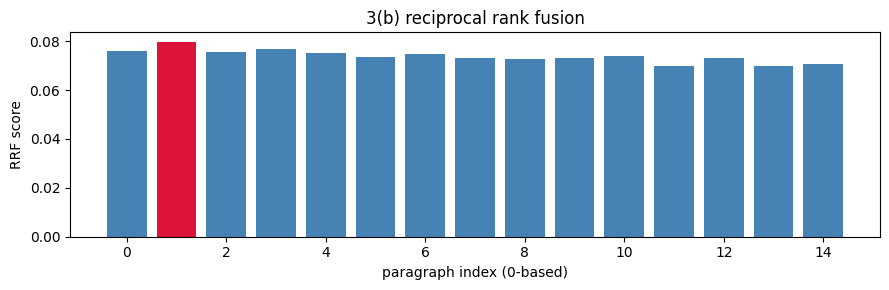

In [12]:
def clip_ranking(paragraphs, img_path):
    import torch
    from PIL import Image
    from transformers import CLIPProcessor, CLIPModel
    mid = "openai/clip-vit-base-patch32"
    proc, model = CLIPProcessor.from_pretrained(mid), CLIPModel.from_pretrained(mid).to(DEVICE).eval()
    inp = proc(text=paragraphs, images=Image.open(img_path).convert("RGB"), return_tensors="pt", padding=True, truncation=True).to(DEVICE)
    with torch.no_grad(): s = model(**inp).logits_per_image.cpu().numpy().ravel()
    return np.argsort(-s), s

def clap_ranking(paragraphs, y, sr):
    import torch
    from transformers import ClapProcessor, ClapModel
    mid = "laion/clap-htsat-unfused"
    proc, model = ClapProcessor.from_pretrained(mid), ClapModel.from_pretrained(mid).to(DEVICE).eval()
    y48 = librosa.resample(y.astype(np.float32), orig_sr=sr, target_sr=48000)
    try:   inp = proc(text=paragraphs, audio=y48, sampling_rate=48000, return_tensors="pt", padding=True)
    except (TypeError, ValueError): inp = proc(text=paragraphs, audios=y48, sampling_rate=48000, return_tensors="pt", padding=True)
    inp = {k: v.to(DEVICE) for k, v in inp.items()}
    with torch.no_grad(): s = model(**inp).logits_per_audio.cpu().numpy().ravel()
    return np.argsort(-s), s

def rrf(orders: Dict[str, np.ndarray], n, k=60):
    sc = np.zeros(n)
    for o in orders.values():
        for r, d in enumerate(o, 1): sc[d] += 1.0 / (k + r)
    return sc

all_orders = dict(text_orders)
for name, fn in (("clip", lambda: clip_ranking(kb, wm_img_path)), ("clap", lambda: clap_ranking(kb, y_den, sr))):
    try:
        all_orders[name], sc = fn(); logger.info(f"3(b) {name.upper()} top-3 paragraph indices (0-based): {all_orders[name][:3].tolist()}")
    except Exception as e:
        logger.info(f"!! {name.upper()} ranking unavailable ({type(e).__name__}: {e}) - fusing the remaining rankings")

fused_scores = rrf(all_orders, len(kb))
fused_paragraph_index = int(np.argmax(fused_scores))
mm = {k: v for k, v in all_orders.items() if k in ("clip", "clap")}
logger.info(f"3(b) rankings fused: {list(all_orders)} | RRF top-1 paragraph (0-based) = {fused_paragraph_index}"
            + (f" | label-free only (CLIP+CLAP) = {int(np.argmax(rrf(mm, len(kb))))}" if mm else ""))
fig, ax = plt.subplots(figsize=(9, 3)); ax.bar(range(len(kb)), fused_scores, color=["crimson" if i == fused_paragraph_index else "steelblue" for i in range(len(kb))])
ax.set_xlabel("paragraph index (0-based)"); ax.set_ylabel("RRF score"); ax.set_title("3(b) reciprocal rank fusion"); plt.tight_layout(); plt.savefig(f"rrf_{ROLL_NUMBER}.png", dpi=140); plt.show()

### 3(c) Vocalisations in the fused top-1 paragraph, and 3(d) why a substring search for "cat" fails

In [13]:
def extract_vocalisations(par):
    p = par.replace("\u2014", " - ")
    found = []
    # (1) "<gerund> [, <gerund>] and <gerund> vocalizations"  e.g. "loud, high-pitched crowing vocalizations", "bleating and baaing vocalizations"
    for m in re.finditer(r"((?:[a-z]+ing)(?:\s*,\s*[a-z]+ing)*(?:\s*,?\s*(?:and|or)\s+[a-z]+ing)?)\s+vocalizations", p, re.I):
        found += re.findall(r"[a-z]+ing", m.group(1).lower())
    # (2) "vocalizations (such as|include|known as) a, b, and c"
    for m in re.finditer(r"vocalizations\s+(?:such as|include|including|known as)\s+(.+?)(?:\.|;|\s+alongside|,\s+which|\s+which|$)", p, re.I):
        found += [w for w in re.findall(r"[a-z]+ing", m.group(1).lower())]
    seen, out = set(), []
    for w in found:
        if w not in seen: seen.add(w); out.append(w)
    return out

top_par = kb[fused_paragraph_index]
vocalisations = extract_vocalisations(top_par)
logger.info(f"3(c) top-1 paragraph [{fused_paragraph_index}]: {top_par}")
logger.info(f"3(c) vocalisations: {vocalisations}")

print("\n=== 3(d) Why a plain substring search for 'cat' returns the wrong paragraph ===")
sub_hits = {i: [m.group(0) for m in re.finditer(r"\w*cat\w*", p, re.I)] for i, p in enumerate(kb) if "cat" in p.lower()}
word_hits = [i for i, p in enumerate(kb) if re.search(r"\bcat\b", p, re.I)]
for i, w in sub_hits.items(): print(f"  paragraph {i:2d}: substring 'cat' found inside {sorted(set(w))}")
first = min(sub_hits)
print(f"\n`'cat' in paragraph.lower()` is True for {len(sub_hits)} paragraphs ({sorted(sub_hits)}). The FIRST hit is paragraph {first} "
      f"(\"{kb[first][:45]}...\"), which is not about a cat: the letters c-a-t occur inside 'domesticated', 'Cattle', 'communicate', 'communication', 'location', ...\n"
      f"Only a whole-word match (regex \\bcat\\b) or a retrieval model that works on tokens/meaning isolates the cat paragraph(s): {word_hits}.\n"
      f"A substring test knows characters, not words - it needs word-boundary tokenisation (TF-IDF/BM25) or semantics (embeddings).")

[08:10:00] 3(c) top-1 paragraph [1]: A rooster, also known as a cockerel or adult male chicken (Gallus gallus domesticus), is a domesticated gallinaceous bird. Roosters are territorial birds famous for their loud, high-pitched crowing vocalizations—often heard at dawn—to assert dominance and warn rival birds on the farm.
[08:10:00] 3(c) vocalisations: ['crowing']



=== 3(d) Why a plain substring search for 'cat' returns the wrong paragraph ===
  paragraph  1: substring 'cat' found inside ['domesticated']
  paragraph  3: substring 'cat' found inside ['cat', 'catus', 'communicates']
  paragraph  6: substring 'cat' found inside ['communication', 'domesticated']
  paragraph  9: substring 'cat' found inside ['Cattle', 'communicate', 'domesticated']
  paragraph 10: substring 'cat' found inside ['communicate', 'location']
  paragraph 11: substring 'cat' found inside ['communication']

`'cat' in paragraph.lower()` is True for 6 paragraphs ([1, 3, 6, 9, 10, 11]). The FIRST hit is paragraph 1 ("A rooster, also known as a cockerel or adult ..."), which is not about a cat: the letters c-a-t occur inside 'domesticated', 'Cattle', 'communicate', 'communication', 'location', ...
Only a whole-word match (regex \bcat\b) or a retrieval model that works on tokens/meaning isolates the cat paragraph(s): [3].
A substring test knows characters, not words - it needs wo

## Export `result.json`, `restored.png` and sanity checks
The checks below only verify format / consistency (e.g. `n_fft` follows the roll-number rule, the image has the right size) — they do not compare with remembered answers.

In [14]:
result = {
    "roll": ROLL_NUMBER,
    "n_fft": int(N_FFT),
    "tones_hz": [float(t) for t in tones_hz],
    "num_events": int(num_events),
    "median_f0_hz": round(float(median_f0_hz), 2),
    "watermarked_image": os.path.basename(wm_img_path),
    "watermark_bbox": [int(v) for v in watermark_bbox],
    "paragraph_ranks": {k: int(paragraph_ranks[k]) for k in ("tfidf", "bm25", "embedding") if k in paragraph_ranks},
    "fused_paragraph_index": int(fused_paragraph_index),
    "vocalisations": vocalisations,
}
for name in ("result.json", f"result_{ROLL_NUMBER}.json"):
    json.dump(result, open(name, "w"), indent=2)
print(json.dumps(result, indent=2))

# ---- format / consistency checks
assert result["n_fft"] == 512 + 64 * (int(ROLL_NUMBER[-2:]) % 8)
assert result["tones_hz"] and all(0 < t < sr / 2 for t in result["tones_hz"])
assert result["num_events"] == len(events) and np.isfinite(result["median_f0_hz"])
bx1, by1, bx2, by2 = result["watermark_bbox"]; assert 0 <= bx1 < bx2 <= 511 and 0 <= by1 < by2 <= 511
assert 0 <= result["fused_paragraph_index"] < len(kb)
assert set(result["paragraph_ranks"]) == {"tfidf", "bm25", "embedding"}, "a text-ranking model failed to load - re-run the cell"
assert cv2.imread("restored.png").shape == (512, 512, 3)
for a in ("clip", "clap"): assert a in all_orders, f"{a.upper()} ranking missing - result.json would not follow the exam recipe"
print("\nAll sanity checks passed. Files: result.json, restored.png, this notebook.")

{
  "roll": "MAI2026006",
  "n_fft": 896,
  "tones_hz": [
    80.0,
    120.0,
    5200.0,
    6000.0
  ],
  "num_events": 1,
  "median_f0_hz": 2200.81,
  "watermarked_image": "img_05.jpg",
  "watermark_bbox": [
    21,
    469,
    229,
    486
  ],
  "paragraph_ranks": {
    "tfidf": 1,
    "bm25": 1,
    "embedding": 1
  },
  "fused_paragraph_index": 1,
  "vocalisations": [
    "crowing"
  ]
}

All sanity checks passed. Files: result.json, restored.png, this notebook.


In [15]:
# ---- Download all required deliverables packaged in a zip file ----
import os, glob, zipfile

zip_filename = f"MMDP_Lab_Exam_2_{ROLL_NUMBER}.zip"

# Core required deliverables specified by the exam
candidates = [
    "result.json",
    f"result_{ROLL_NUMBER}.json",
    "restored.png",
    f"restored_{ROLL_NUMBER}.png",
    f"Lab_Exam_2_{ROLL_NUMBER}.ipynb",
    f"/content/Lab_Exam_2_{ROLL_NUMBER}.ipynb",
    f"execution_{ROLL_NUMBER}.log",
]

# Include all generated diagnostic figures and logs
candidates.extend(glob.glob(f"*{ROLL_NUMBER}*.png"))
candidates.extend(glob.glob("*.log"))

# Build unique file list preserving order
to_package = []
seen_basenames = set()
for p in candidates:
    if os.path.exists(p):
        bname = os.path.basename(p)
        if bname not in seen_basenames:
            seen_basenames.add(bname)
            to_package.append((p, bname))

# Package into zip archive
with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zf:
    print(f"Packaging deliverables into '{zip_filename}':")
    for src, arc in to_package:
        zf.write(src, arcname=arc)
        size_kb = os.path.getsize(src) / 1024.0
        print(f"  ✓ {arc:<35s} ({size_kb:6.1f} KB)")

zip_size_kb = os.path.getsize(zip_filename) / 1024.0
print(f"\nCreated submission zip package: {zip_filename} ({zip_size_kb:.1f} KB)")

# Trigger automatic browser download in Colab
try:
    from google.colab import files
    print(f"Triggering download of {zip_filename} ...")
    files.download(zip_filename)
except Exception as e:
    print(f"Note: Colab files.download skipped (not in Colab or blocked: {e})")


Packaging deliverables into 'MMDP_Lab_Exam_2_MAI2026006.zip':
  ✓ result.json                         (   0.4 KB)
  ✓ result_MAI2026006.json              (   0.4 KB)
  ✓ restored.png                        ( 334.0 KB)
  ✓ restored_MAI2026006.png             ( 334.0 KB)
  ✓ execution_MAI2026006.log            (   1.9 KB)
  ✓ watermark_bbox_MAI2026006.png       ( 241.5 KB)
  ✓ spectrograms_MAI2026006.png         (1363.5 KB)
  ✓ restoration_MAI2026006.png          ( 291.5 KB)
  ✓ watermark_scores_MAI2026006.png     (  52.6 KB)
  ✓ tones_MAI2026006.png                (  64.7 KB)
  ✓ events_MAI2026006.png               (  72.8 KB)
  ✓ rrf_MAI2026006.png                  (  25.0 KB)

Created submission zip package: MMDP_Lab_Exam_2_MAI2026006.zip (2583.4 KB)
Triggering download of MMDP_Lab_Exam_2_MAI2026006.zip ...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>